# Codveda ML Internship - Level 1, Task 3: K-Nearest Neighbors (KNN) Classifier


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print(X.shape); X.head()

(569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Split and scale
KNN is distance-based, so features must be scaled. The scaler is fit on the training set only.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

### Compare different values of K

In [3]:
rows = []
for k in [1, 3, 5, 7, 9, 11, 15, 21]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    p = knn.predict(X_test_s)
    rep = classification_report(y_test, p, output_dict=True)
    rows.append({"K": k, "accuracy": accuracy_score(y_test, p),
                 "precision(benign)": rep["1"]["precision"], "recall(benign)": rep["1"]["recall"]})
results = pd.DataFrame(rows).set_index("K").round(3)
results

,accuracy,precision(benign),recall(benign)
K,,,
1,0.939,0.958,0.944
3,0.982,0.973,1.000
5,0.956,0.959,0.972
7,0.974,0.960,1.000
9,0.974,0.960,1.000
11,0.974,0.960,1.000
15,0.974,0.960,1.000
21,0.965,0.947,1.000


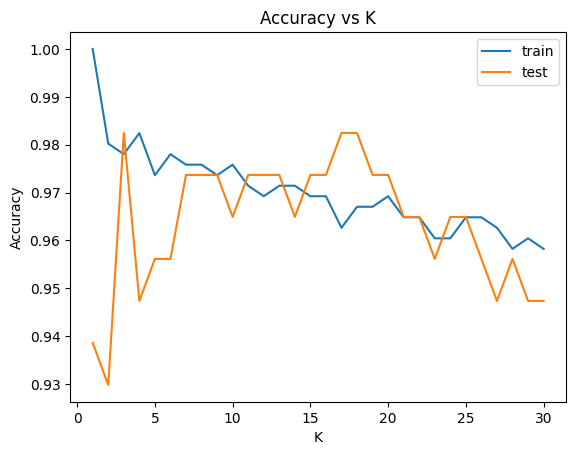

Best K on test set: 3


In [4]:
ks = range(1, 31)
test_acc = [KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train).score(X_test_s, y_test) for k in ks]
train_acc = [KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train).score(X_train_s, y_train) for k in ks]
plt.plot(ks, train_acc, label="train"); plt.plot(ks, test_acc, label="test")
plt.xlabel("K"); plt.ylabel("Accuracy"); plt.title("Accuracy vs K"); plt.legend()
plt.savefig("knn_accuracy_vs_k.png", dpi=150); plt.show()
best_k = ks[int(np.argmax(test_acc))]
print("Best K on test set:", best_k)

### Detailed evaluation for the chosen K

Accuracy: 0.982
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        42
      benign       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



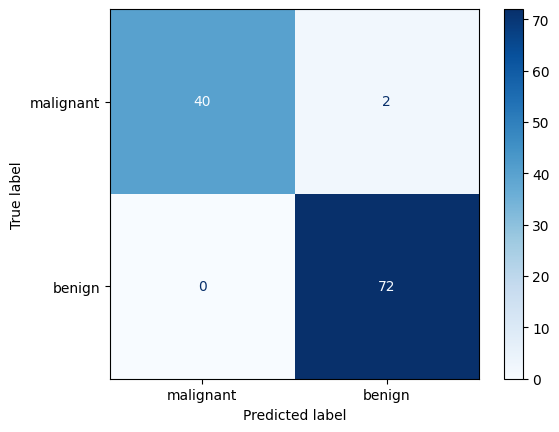

In [5]:
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
pred = knn.predict(X_test_s)
print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, target_names=data.target_names))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=data.target_names).plot(cmap="Blues")
plt.savefig("knn_confusion_matrix.png", dpi=150); plt.show()